# Multi-site research through the Afon data fabric

## Objective of the Notebook

- Demonstrate how synthetic data held in multiple SDEs can be automatically brought together whilst maintaining local governance control and minimising data movement through a representative research question.
- Compare this approach to single site analysis eyes off federated analysis


### Research Context

Epidermal growth factor receptor (EGFR) mutations are the most common oncogenic drivers in non-small-cell lung cancer (NSCLC). This project uses synthetic real world data to estimate the impact of different treatment regimens on patient outcomes


**Research Question.** Among patients with advanced (stage IIIB/IV) EGFR-mutant NSCLC, does first-line
osimertinib reduce 12-month progression compared with a platinum doublet?

**Setting.** We are linking data between the WestMidlands SDE (Azure), Thames Valley and Surrey SDE (Azure) and a central data store (AWS) each holding their own FHIR-derived data.

**Data**

**Plan.**
1. Load per-site cohorts and describe case-mix
2. State the DAG and identify the estimand 
3. Estimate per site effect 
4. Hierarchical Bayesian model across sites (PyMC)
5. Federated variant: sites share only posterior summaries
6. Score everything against ground truth

In [1]:
import sys, warnings
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import analysis as A
from src import cohort

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
SITES = ("aws", "azure", "gcp")
DATA = ROOT / "output"
SEED = 2024


# uv run python generate_synthetic_ehr.py --patients 800 --site aws --seed 1 --output output/aws 
# uv run python generate_synthetic_ehr.py --patients 800 --site azure --seed 2 --output output/azure 
# uv run python generate_synthetic_ehr.py --patients 800 --site gcp --seed 3 --output output/gcp

## 1. Load site cohorts

Each site creates the input dataa locally on its own four FHIR tables. The output is one row
per eligible patient with baseline covariates (last value on or before treatment start), a binary
treatment indicator and the 12-month outcome.

In [2]:
frames = []
for s in SITES:
    tables = cohort.load_site(DATA / s)
    site_df = cohort.build_lung_cohort(tables, advanced_only=True)
    cohort.write_site_artifact(site_df, ROOT / "output" / s / "cohort.parquet")
    frames.append(site_df)
df = pd.concat(frames, ignore_index=True)
pos = df[df["egfr_positive"] == 1].reset_index(drop=True)
neg = df[df["egfr_positive"] == 0].reset_index(drop=True)
print(f"advanced-stage cohort: {len(df)} patients; EGFR+ {len(pos)}, EGFR- {len(neg)}")


advanced-stage cohort: 1589 patients; EGFR+ 560, EGFR- 1029


### Table one — case-mix differs by site

In [3]:
def table_one(d):
    g = d.groupby("site")
    out = pd.DataFrame({
        "n": g.size(),
        "Age": g["age"].mean().round(1),
        "Female ratio": g["female"].mean().round(2),
        "Never Smoker": g["never_smoker"].mean().round(2),
        "EFGR + ratio": g["egfr_positive"].mean().round(2)
    })
    return out

table_one(df)

,n,Age,Female ratio,Never Smoker,EFGR + ratio
site,,,,,
aws,486,60.8,0.50,0.20,0.34
azure,520,60.5,0.52,0.28,0.40
gcp,583,61.2,0.53,0.15,0.32


## 2. Causal graph and identification

The assumed DAG matches clinical reasoning (and, here, the generator): age, sex, stage, ECOG,
albumin and smoking history influence both prescribing and progression. Within the EGFR+ stratum
EGFR status is constant, so it drops out. DoWhy confirms the back-door adjustment set.

In [4]:
model, estimand = A.dowhy_model(pos)
print(A.causal_graph_dot())
print()
print("Back-door adjustment set:", estimand.get_backdoor_variables())

digraph {
  treatment -> progression_12m;
  age -> treatment;
  age -> progression_12m;
  age -> ecog_ge2;
  female -> treatment;
  female -> progression_12m;
  stage_iv -> treatment;
  stage_iv -> progression_12m;
  stage_iv -> ecog_ge2;
  stage_iv -> albumin;
  ecog_ge2 -> treatment;
  ecog_ge2 -> progression_12m;
  ecog_ge2 -> albumin;
  albumin -> treatment;
  albumin -> progression_12m;
  never_smoker -> treatment;
  never_smoker -> progression_12m;
}

Back-door adjustment set: ['stage_iv', 'albumin', 'age', 'female', 'ecog_ge2', 'never_smoker']


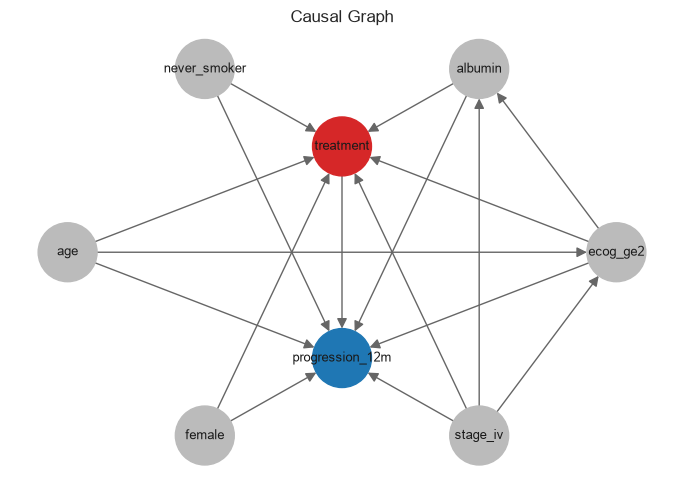

In [5]:
import networkx as nx
g = A.causal_graph()
posn = nx.shell_layout(g, nlist=[[A.TREATMENT, A.OUTCOME], A.COVARIATES])
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#d62728" if n == A.TREATMENT else "#1f77b4" if n == A.OUTCOME else "#bbbbbb" for n in g.nodes]
nx.draw_networkx(g, posn, ax=ax, node_color=colors, node_size=1800, font_size=9, arrowsize=15, edge_color="#666")
ax.set_axis_off(); ax.set_title("Causal Graph")
plt.tight_layout()

## 4. Modelling the effects

A Bayesian model to test the causal graph we have seen

In [27]:
prior = A.fit_hierarchical(df, draws=500, prior_only=True, seed=SEED)
idata = A.fit_hierarchical(df, draws=1000, tune=1000, chains=4, seed=SEED)
# summ = A.convergence_summary(idata, ["mu_tau", "sigma_tau", "tau_site", "tau_neg", "ate_rd_egfr_pos", "ate_rd_egfr_neg", "ate_rd_site"])
# print("divergences:", summ.attrs["divergences"])
# summ[["mean", "sd", "hdi_3%", "hdi_97%", "ess_bulk", "r_hat"]]

Sampling: [beta, beta_egfr, mu_alpha, mu_tau, sigma_alpha, sigma_tau, tau_neg, y, z_alpha, z_tau]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_tau, sigma_tau, z_tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
Sampling: [y]


## 5. Federated variant

Patient-level data never leave a site. Each site fits its own Bayesian model and shares only the
posterior **mean and sd** of the EGFR+ risk difference. A coordinator combines these with a
random-effects meta-analysis. This is a one-shot, privacy-preserving approximation to the
hierarchical model above.

In [29]:
site_idatas = {s: A.fit_site_model(df[df["site"] == s], draws=1000, tune=1000, chains=4, seed=SEED) for s in SITES}

summaries = [A.site_summary(site_idatas[s], s) for s in SITES]

meta = A.meta_analysis(summaries, seed=SEED)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, tau_between, z]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


## 6. Score against ground truth

Now — and only now — we compare these approaches with the ground truth. The target is the sample-average true
risk difference $\frac{1}{n}\sum_i (p_{1i} - p_{0i})$ over the analysed EGFR+ patients.

In [30]:
truth = A.load_truth(DATA, SITES)
tv_pos = A.true_rd(truth, pos["patient_id"], egfr=1)
tv_neg = A.true_rd(truth, neg["patient_id"], egfr=0)
tv_site = {s: A.true_rd(truth, pos.loc[pos["site"] == s, "patient_id"]) for s in SITES}
print(f"true RD  EGFR+: {tv_pos:.4f} ")


true RD  EGFR+: -0.2818 


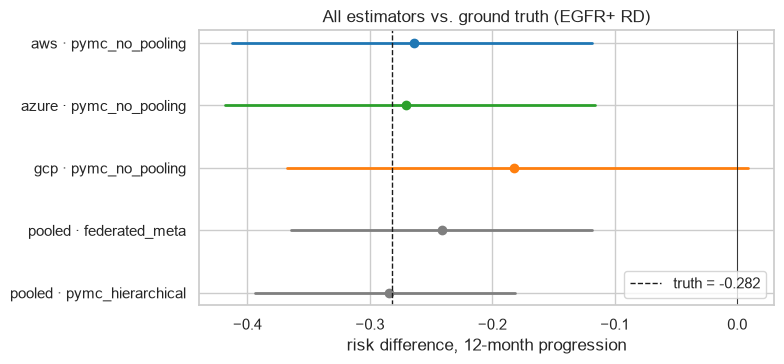

In [34]:
bayes_rows = [
    {"site": "pooled", "method": "pymc_hierarchical", **A.posterior_interval(idata, "ate_rd_egfr_pos"), "n": len(pos)},
    {"site": "pooled", "method": "federated_meta", **A.posterior_interval(meta, "mu"), "n": len(pos)},
]
for s in SITES:
    bayes_rows.append({"site": s, "method": "pymc_no_pooling", **A.posterior_interval(site_idatas[s], "ate_rd_egfr_pos"), "n": int((pos["site"] == s).sum())})
    hd = az.hdi(idata.posterior["ate_rd_site"].sel(site=s), hdi_prob=0.95)["ate_rd_site"].to_numpy()
    bayes_rows.append({"site": s, "method": "pymc_partial_pooling", "estimate": idata.posterior["ate_rd_site"].sel(site=s).mean().item(),
                       "ci_low": float(hd[0]), "ci_high": float(hd[1]), "n": int((pos["site"] == s).sum())})
all_est = pd.concat([pd.DataFrame(bayes_rows)], ignore_index=True)
scored = A.score_estimates(all_est, tv_pos)
scored["truth"] = scored["site"].map(tv_site).fillna(tv_pos)
scored["bias"] = scored["estimate"] - scored["truth"]
scored["covered"] = (scored["ci_low"] <= scored["truth"]) & (scored["truth"] <= scored["ci_high"])
included_methods = ["pymc_no_pooling","pymc_hierarchical","federated_meta"]
scored.loc[scored.method.isin(included_methods),:].sort_values(["site", "method"]).round(3)

## Plot the output
fig, ax = plt.subplots(figsize=(8, 0.35 * len(scored) + 1))
forest(scored.loc[scored.method.isin(included_methods),:].sort_values(["site", "method"]), truth=tv_pos, title="All estimators vs. ground truth (EGFR+ RD)", ax=ax)
plt.tight_layout()


## 10. What this shows

- **Confounding by indication is large and direction-dependent.** Crude EGFR− estimates suggest harm; adjustment removes it.
- **Single sites are not enough.** With 13–29 EGFR+ controls per site, per-site IPW/AIPW intervals span zero or miss the truth; the smallest site is essentially uninformative on its own.
- **Partial pooling fixes this without assuming homogeneity.** Site-specific effects shrink toward a common mean with honest uncertainty; `sigma_tau` quantifies how much sites genuinely differ.
- **The federated summary-sharing variant recovers most of the benefit** of the full hierarchical model while never moving patient-level rows.
- **Refutations and the negative control** behave as they should, which is what a reviewer would look for before believing the headline effect.

Re-run with `--unmeasured-confounding strong` in the generator to see every estimator drift and the
sensitivity refuter become the most important row in the table.